In [3]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from huggingface_hub import hf_hub_download
from ultralytics import YOLO
from dotenv import load_dotenv
load_dotenv()

REPO_ID = os.getenv("REPO_ID")
MODEL_FILENAME = "models/yolo26n_final_model_best.pt"  # path inside HF repo

LOCAL_TEST_DIR = Path(os.getenv("EXTRACTED_DATA_PATH")) / "test"  # Update this to your local path

OUTPUT_ANALYSIS_DIR = Path("./model_analysis")
OUTPUT_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

FALSE_POS_DIR = OUTPUT_ANALYSIS_DIR / "false_positives"
FALSE_NEG_DIR = OUTPUT_ANALYSIS_DIR / "false_negatives"
FALSE_POS_DIR.mkdir(parents=True, exist_ok=True)
FALSE_NEG_DIR.mkdir(parents=True, exist_ok=True)


# =====================================================================
# 1. HUGGING FACE WEIGHTS DOWNLOADER
# =====================================================================
def download_weights() -> Path:
    print(f"[*] Downloading weights '{MODEL_FILENAME}' from HF Repo '{REPO_ID}'...")
    try:
        weights_path = hf_hub_download(
            repo_id=REPO_ID, 
            filename=MODEL_FILENAME, 
            repo_type="dataset"
        )
        print(f"[+] Weights successfully downloaded to: {weights_path}")
        return Path(weights_path)
    except Exception as e:
        print(f"[!] HF Download failed: {e}")
        raise e


# =====================================================================
# 2. MATHEMATICAL HELPERS (IoU & Coordinates)
# =====================================================================
def calculate_iou(box1, box2):
    """Calculates Intersection over Union (IoU) of two boxes [x1, y1, x2, y2]."""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    
    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection
    
    return intersection / union if union > 0 else 0.0


# =====================================================================
# 3. CORE EVALUATION & THRESHOLD SWEEP ENGINE
# =====================================================================
def run_deep_evaluation(model_path: Path):
    print("[*] Loading YOLO model...")
    model = YOLO(str(model_path))
    
    test_pos_dir = LOCAL_TEST_DIR / "RAW_POSITIVES"
    test_neg_dir = LOCAL_TEST_DIR / "RAW_NEGATIVES"
    
    # Check if directories exist
    if not test_pos_dir.exists() or not test_neg_dir.exists():
        raise FileNotFoundError(f"Please check LOCAL_TEST_DIR path. Directories not found in: {LOCAL_TEST_DIR}")
        
    image_paths = []
    for ext in ["*.jpg", "*.png", "*.jpeg"]:
        image_paths.extend(list(test_pos_dir.glob(ext)))
        image_paths.extend(list(test_neg_dir.glob(ext)))
        
    print(f"[*] Found {len(image_paths)} images in the test set. Starting inference pass...")
    
    # Store all ground truths and raw model predictions (with low confidence to sweep later)
    # Each entry: { 'img_path': Path, 'gt_boxes': [[x1, y1, x2, y2]], 'pred_boxes': [[x1, y1, x2, y2, conf]] }
    eval_data = []
    
    for idx, img_path in enumerate(image_paths):
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        
        # Parse Ground Truth
        gt_boxes = []
        is_positive = "RAW_POSITIVES" in str(img_path)
        
        if is_positive:
            txt_path = img_path.with_suffix(".txt")
            if txt_path.exists():
                with open(txt_path, "r") as f:
                    for line in f.readlines():
                        parts = line.strip().split()
                        if len(parts) >= 5:
                            x_c, y_c, bw, bh = map(float, parts[1:5])
                            x1 = (x_c - bw/2.0) * w
                            y1 = (y_c - bh/2.0) * h
                            x2 = (x_c + bw/2.0) * w
                            y2 = (y_c + bh/2.0) * h
                            gt_boxes.append([x1, y1, x2, y2])
                            
        # Run inference with very low confidence limit to get full prediction distribution
        # Disable augmentations for pure testing
        results = model.predict(img_path, conf=0.01, verbose=False, augment=False)[0]
        
        pred_boxes = []
        if results.boxes is not None:
            for box in results.boxes:
                xyxy = box.xyxy[0].tolist()  # [x1, y1, x2, y2]
                conf = float(box.conf[0])
                pred_boxes.append(xyxy + [conf])
                
        eval_data.append({
            "img_path": img_path,
            "is_positive": is_positive,
            "gt_boxes": gt_boxes,
            "pred_boxes": pred_boxes
        })
        
        if (idx + 1) % 250 == 0:
            print(f"    Processed {idx + 1}/{len(image_paths)} images...")

    # Sweep confidence thresholds from 0.05 to 0.95 to find optimal post-processing config
    thresholds = np.linspace(0.05, 0.95, 19)
    precision_curve = []
    recall_curve = []
    f1_curve = []
    neg_false_alarm_rate = []  # Percentage of negatives that trigger false alarms
    
    # For centroid error tracking (at optimal threshold)
    centroid_errors = []

    print("[*] Performing threshold sweep for calibration...")
    for th in thresholds:
        tp_total = 0
        fp_total = 0
        fn_total = 0
        
        total_negatives = 0
        negatives_with_false_alarms = 0
        
        for data in eval_data:
            gt = data["gt_boxes"]
            # Filter predictions by current threshold
            preds = [p for p in data["pred_boxes"] if p[4] >= th]
            
            if not data["is_positive"]:
                total_negatives += 1
                if len(preds) > 0:
                    negatives_with_false_alarms += 1
            
            # Match predictions to GT via IoU
            matched_gt = set()
            for p in preds:
                best_iou = 0.0
                best_gt_idx = -1
                for g_idx, g in enumerate(gt):
                    if g_idx in matched_gt:
                        continue
                    iou = calculate_iou(p[:4], g)
                    if iou > best_iou:
                        best_iou = iou
                        best_gt_idx = g_idx
                        
                if best_iou >= 0.5:
                    tp_total += 1
                    matched_gt.add(best_gt_idx)
                    
                    # Calculate centroid error for True Positives on the sweep closest to 0.5
                    if abs(th - 0.5) < 0.01:
                        # Centroids
                        c_p = ((p[0] + p[2])/2.0, (p[1] + p[3])/2.0)
                        c_g = ((gt[best_gt_idx][0] + gt[best_gt_idx][2])/2.0, (gt[best_gt_idx][1] + gt[best_gt_idx][3])/2.0)
                        dist = np.sqrt((c_p[0] - c_g[0])**2 + (c_p[1] - c_g[1])**2)
                        centroid_errors.append(dist)
                else:
                    fp_total += 1
                    
            fn_total += (len(gt) - len(matched_gt))
            
        precision = tp_total / (tp_total + fp_total) if (tp_total + fp_total) > 0 else 1.0
        recall = tp_total / (tp_total + fn_total) if (tp_total + fn_total) > 0 else 0.0
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        neg_fa_rate = (negatives_with_false_alarms / total_negatives * 100) if total_negatives > 0 else 0.0
        
        precision_curve.append(precision)
        recall_curve.append(recall)
        f1_curve.append(f1)
        neg_false_alarm_rate.append(neg_fa_rate)

    # Find mathematically optimal threshold (max F1)
    best_idx = np.argmax(f1_curve)
    opt_th = thresholds[best_idx]
    
    print("\n" + "="*60)
    print("                CALIBRATION RESULTS                         ")
    print("============================================================")
    print(f"Optimal Confidence Threshold (Max F1)  : {opt_th:.2f}")
    print(f"Precision at Optimal Threshold         : {precision_curve[best_idx]:.4f}")
    print(f"Recall at Optimal Threshold            : {recall_curve[best_idx]:.4f}")
    print(f"Max F1-Score                           : {f1_curve[best_idx]:.4f}")
    print(f"False Alarm Rate on Negatives at Opt Th: {neg_false_alarm_rate[best_idx]:.2f}%")
    if centroid_errors:
        print(f"Mean Centroid Localization Error       : {np.mean(centroid_errors):.2f} pixels")
        print(f"Centroid Error Std Dev                 : {np.std(centroid_errors):.2f} pixels")
    print("============================================================")

    # Plotting Curves
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(thresholds, precision_curve, 'g-', label='Precision')
    plt.plot(thresholds, recall_curve, 'b-', label='Recall')
    plt.plot(thresholds, f1_curve, 'r--', label='F1-Score')
    plt.axvline(opt_th, color='black', linestyle=':', label=f'Optimal Th ({opt_th:.2f})')
    plt.xlabel('Confidence Threshold')
    plt.ylabel('Score')
    plt.title('Threshold Calibration Curves')
    plt.legend()
    plt.grid(True)
    
    plt.subplot(1, 2, 2)
    plt.plot(thresholds, neg_false_alarm_rate, 'm-')
    plt.axvline(opt_th, color='black', linestyle=':')
    plt.xlabel('Confidence Threshold')
    plt.ylabel('False Alarm Rate on Negatives (%)')
    plt.title('Watermark/Noise Vulnerability Rate')
    plt.grid(True)
    
    plot_path = OUTPUT_ANALYSIS_DIR / "calibration_curves.png"
    plt.savefig(plot_path)
    plt.show()
    print(f"[+] Saved analysis plots to: {plot_path}")

    # =====================================================================
    # 4. FAILURE ANALYSIS EXPORTER (For Thesis Visuals)
    # =====================================================================
    print("\n[*] Exporting worst failure cases for visual inspection...")
    fp_exported = 0
    fn_exported = 0
    
    for data in eval_data:
        img_path = data["img_path"]
        gt = data["gt_boxes"]
        preds = [p for p in data["pred_boxes"] if p[4] >= opt_th]
        
        img = cv2.imread(str(img_path))
        
        # Case A: False Positive on Negative Frame (Vulnerability to watermarks/noise)
        if not data["is_positive"] and len(preds) > 0 and fp_exported < 10:
            for p in preds:
                cv2.rectangle(img, (int(p[0]), int(p[1])), (int(p[2]), int(p[3])), (0, 0, 255), 2)
                cv2.putText(img, f"FP Conf: {p[4]:.2f}", (int(p[0]), int(p[1]-5)), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
            cv2.imwrite(str(FALSE_POS_DIR / img_path.name), img)
            fp_exported += 1
            
        # Case B: False Negative (Drone missed completely)
        if data["is_positive"] and len(preds) == 0 and fn_exported < 10:
            for g in gt:
                cv2.rectangle(img, (int(g[0]), int(g[1])), (int(g[2]), int(g[3])), (0, 255, 255), 2)
                cv2.putText(img, "Missed Drone (FN)", (int(g[0]), int(g[1]-5)), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
            cv2.imwrite(str(FALSE_NEG_DIR / img_path.name), img)
            fn_exported += 1
            
    print(f"[+] Exported {fp_exported} False Positive images to: '{FALSE_POS_DIR}'")
    print(f"[+] Exported {fn_exported} False Negative images to: '{FALSE_NEG_DIR}'")

d:\anykn\python\bachelor\drone_classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[*] Downloading weights 'models/yolo26n_final_model_best.pt' from HF Repo 'hannusia123123/drone_dataset'...
[+] Weights successfully downloaded to: C:\Users\anykn\.cache\huggingface\hub\datasets--hannusia123123--drone_dataset\snapshots\b8764f4af7600e330683295f12cc245cd3281209\models\yolo26n_final_model_best.pt
[*] Loading YOLO model...
[*] Found 2524 images in the test set. Starting inference pass...
    Processed 250/2524 images...
    Processed 500/2524 images...
    Processed 750/2524 images...
    Processed 1000/2524 images...
    Processed 1250/2524 images...
    Processed 1500/2524 images...
    Processed 1750/2524 images...
    Processed 2000/2524 images...
    Processed 2250/2524 images...
    Processed 2500/2524 images...
[*] Performing threshold sweep for calibration...

                CALIBRATION RESULTS                         
Optimal Confidence Threshold (Max F1)  : 0.35
Precision at Optimal Threshold         : 0.8982
Recall at Optimal Threshold            : 0.8084
Max F

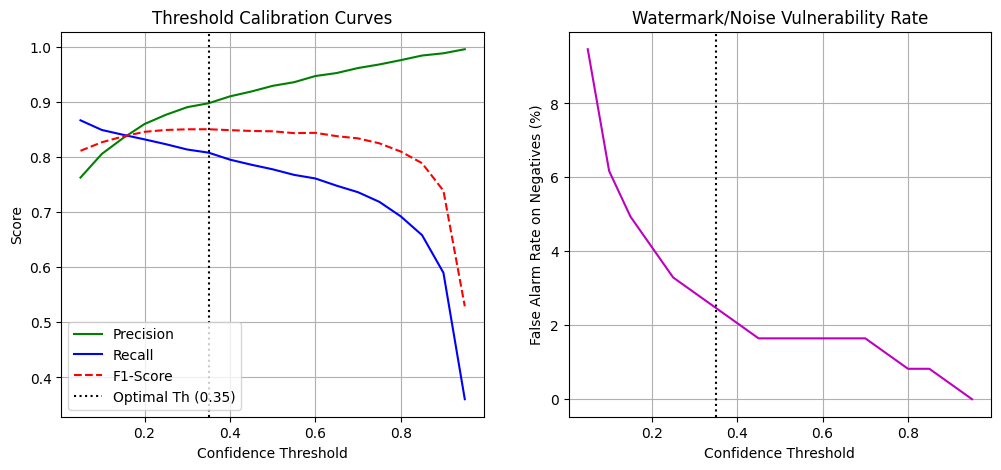

[+] Saved analysis plots to: model_analysis\calibration_curves.png

[*] Exporting worst failure cases for visual inspection...
[+] Exported 6 False Positive images to: 'model_analysis\false_positives'
[+] Exported 10 False Negative images to: 'model_analysis\false_negatives'


In [ ]:
if __name__ == "__main__":
    weights = download_weights()
    run_deep_evaluation(weights)

In [6]:
import os
import glob
import cv2
import yaml
from pathlib import Path
from ultralytics import YOLO

# =====================================================================
# CONFIGURATION
# =====================================================================
VIDEO_PATH = Path(os.getenv("LOCAL_BASE_DIR")) / "labels" / "test" / "delta_rgb_sky_100.mp4"
LABELS_DIR = Path(os.getenv("LOCAL_BASE_DIR")) / "labels" / "test"

CONF_THRESHOLD = 0.35  # Custom confidence threshold


def parse_mot_11_labels(label_path: Path) -> dict:
    """
    Parses a single MOT 1.1 label file into a frame-mapped dictionary.
    Format: <frame>, <id>, <bb_left>, <bb_top>, <bb_width>, <bb_height>, <conf>, <class>, <visibility>
    Returns: dict { frame_id: [(x1, y1, x2, y2, track_id), ...] }
    """
    mot_data = {}
    if not label_path.exists():
        print(f"[WARNING] MOT label file not found at: {label_path}")
        return mot_data

    print(f"[*] Parsing MOT 1.1 annotations from: {label_path}")
    with open(label_path, "r") as f:
        for line in f.readlines():
            line = line.strip()
            if not line:
                continue
            
            # Handle comma or space separation
            parts = line.split(",") if "," in line else line.split()
            if len(parts) < 6:
                continue
                
            try:
                frame_idx = int(parts[0])
                track_id = int(parts[1])
                bb_left = float(parts[2])
                bb_top = float(parts[3])
                bb_width = float(parts[4])
                bb_height = float(parts[5])
                
                # Convert top-left width/height to x1, y1, x2, y2 absolute coordinates
                x1 = int(bb_left)
                y1 = int(bb_top)
                x2 = int(bb_left + bb_width)
                y2 = int(bb_top + bb_height)
                
                if frame_idx not in mot_data:
                    mot_data[frame_idx] = []
                mot_data[frame_idx].append((x1, y1, x2, y2, track_id))
            except ValueError:
                continue
                
    print(f"[+] Successfully parsed annotations for {len(mot_data)} unique frames.")
    return mot_data


def process_continuous_video(weights_path):
    OUTPUT_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
    
    if not VIDEO_PATH.exists():
        raise FileNotFoundError(f"[!] Target video not found at: {VIDEO_PATH}")
        
    video_name = VIDEO_PATH.stem
    # Find matching MOT 1.1 label file in your labels directory
    mot_label_path = LABELS_DIR / f"{video_name}.txt"
    
    # Parse the MOT 1.1 annotations
    mot_annotations = parse_mot_11_labels(mot_label_path)
    
    # Load the trained YOLO model
    print(f"[*] Loading model weights from: {weights_path}")
    model = YOLO(str(weights_path))
    
    # Initialize OpenCV Video Capture
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    if not cap.isOpened():
        print(f"[!] Error opening video file: {VIDEO_PATH}")
        return
        
    orig_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    orig_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    print(f"[*] Video Properties: {orig_w}x{orig_h} | {fps:.2f} FPS | Total Frames: {total_frames}")
    
    # Initialize Video Writer
    output_video_file = OUTPUT_ANALYSIS_DIR / f"{video_name}_evaluated.mp4"
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    out = cv2.VideoWriter(str(output_video_file), fourcc, fps, (orig_w, orig_h))
    
    print(f"[*] Starting video frame-by-frame evaluation...")
    frame_counter = 1  # MOT 1.1 frame indexes are 1-based
    
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break  # End of video stream
            
        # 1. DRAW GROUND TRUTH (RED) FROM MOT 1.1
        if frame_counter in mot_annotations:
            for x1, y1, x2, y2, track_id in mot_annotations[frame_counter]:
                # Draw Red box for original annotation (thickness 2)
                cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 0, 255), 2)
                cv2.putText(frame, f"GT ID: {track_id}", (x1, max(y1-5, 15)), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
                            
        # 2. RUN MODEL PREDICTION & DRAW PREDICTIONS (GREEN)
        results = model.predict(frame, conf=CONF_THRESHOLD, verbose=False, augment=False)[0]
        
        if results.boxes is not None:
            for box in results.boxes:
                px1, py1, px2, py2 = map(int, box.xyxy[0].tolist())
                conf = float(box.conf[0])
                
                # Draw Green box for predictions (thickness 2)
                cv2.rectangle(frame, (px1, py1), (px2, py2), (0, 255, 0), 2)
                cv2.putText(frame, f"YOLO: {conf:.2f}", (px1, max(py1-22, 15)), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
                            
        # Write Frame overlay metadata
        cv2.putText(frame, f"Frame: {frame_counter}/{total_frames} | Th: {CONF_THRESHOLD}", 
                    (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
                    
        # Write processed frame to output video
        out.write(frame)
        
        if frame_counter % 100 == 0:
            print(f"    Evaluated {frame_counter}/{total_frames} frames...")
            
        frame_counter += 1
        
    cap.release()
    out.release()
    
    print("\n" + "="*60)
    print("[SUCCESS] Continuous video evaluation completed successfully!")
    print(f"          Processed video saved to: {output_video_file.resolve()}")
    print("="*60)


if __name__ == "__main__":
    process_continuous_video(weights)

[WARNING] MOT label file not found at: E:\bachelor_data\labels\test\delta_rgb_sky_100.txt
[*] Loading model weights from: C:\Users\anykn\.cache\huggingface\hub\datasets--hannusia123123--drone_dataset\snapshots\b8764f4af7600e330683295f12cc245cd3281209\models\yolo26n_final_model_best.pt
[*] Video Properties: 848x480 | 30.00 FPS | Total Frames: 360
[*] Starting video frame-by-frame evaluation...
    Evaluated 100/360 frames...
    Evaluated 200/360 frames...
    Evaluated 300/360 frames...

[SUCCESS] Continuous video evaluation completed successfully!
          Processed video saved to: D:\anykn\python\bachelor\drone_classification\notebooks\model_analysis\delta_rgb_sky_100_evaluated.mp4


In [ ]:
# =====================================================================
# STEP 1: LIBRARY IMPORTS
# =====================================================================
import os
import glob
import cv2
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from pathlib import Path
from huggingface_hub import hf_hub_download
from ultralytics import YOLO

# Set plotting styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10, 6]

# =====================================================================
# STEP 2: GLOBAL CONFIGURATION
# Set your paths and Hugging Face repository credentials here
# =====================================================================
HF_REPO_ID = "your_hf_username/your_dataset_repo"  # Replace with your HF repo ID
HF_FILENAME = "models/yolo26n_final_model_best.pt" # Replace with your file path in repo
LOCAL_MODEL_PATH = "best_model.pt"

# Set path to your raw local cropped_dataset directory
# (Expected to contain train/val/test splits with RAW_POSITIVES and RAW_NEGATIVES)
LOCAL_DATASET_DIR = Path("cropped_dataset") 

# Target input size of the model during evaluation
IMGSZ = 1280  

# =====================================================================
# STEP 3: MODEL DOWNLOADER FROM HUGGING FACE
# =====================================================================
def download_model_weights():
    print(f"[*] Downloading weights from Hugging Face: {HF_REPO_ID}/{HF_FILENAME}")
    try:
        downloaded_path = hf_hub_download(
            repo_id=HF_REPO_ID, 
            filename=HF_FILENAME, 
            repo_type="dataset"
        )
        # Copy to a clean local file name
        import shutil
        shutil.copy(downloaded_path, LOCAL_MODEL_PATH)
        print(f"[+] Weights successfully saved locally to: {LOCAL_MODEL_PATH}")
    except Exception as e:
        print(f"[WARNING] Hugging Face download failed: {e}")
        print("[!] Please ensure local model file is manually placed if download skipped.")

# Run download
download_model_weights()

# =====================================================================
# STEP 4: CORE GEOMETRY & EVALUATION MATCHING FUNCTIONS
# =====================================================================
def calculate_iou(box1, box2):
    """Calculates Intersection over Union (IoU) of two bounding boxes [x1, y1, x2, y2]."""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    
    inter_area = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    box1_area = (box1[2] - box1[0]) * (box1[3] - box1[1])
    box2_area = (box2[2] - box2[0]) * (box2[3] - box2[1])
    
    union_area = box1_area + box2_area - inter_area
    if union_area == 0:
        return 0.0
    return inter_area / union_area


def parse_filename_metadata(filename):
    """
    Parses metadata from filename using underscores.
    Expected: {morphology}_{camera}_{background}_{video_id}_f{frame_id}.jpg
    Example: delta_rgb_field_072_f0253.jpg
    """
    parts = filename.split('_')
    if len(parts) >= 3:
        morphology = parts[0]
        camera = parts[1]
        background = parts[2]
        return morphology, camera, background
    return "unknown", "unknown", "unknown"


def evaluate_predictions(gt_boxes, pred_boxes, iou_threshold=0.5):
    """
    Matches predictions and ground truths using IoU greedy matching.
    Returns: matched true positive indices, unmatched detection indices (FP), unmatched GT indices (FN)
    """
    if len(pred_boxes) == 0:
        return [], [], list(range(len(gt_boxes)))
    if len(gt_boxes) == 0:
        return [], list(range(len(pred_boxes))), []

    # Sort detections by confidence descending
    pred_boxes = sorted(pred_boxes, key=lambda x: x[4], reverse=True)
    
    matched_gts = set()
    tp_indices = []
    fp_indices = []
    
    for pred_idx, pred in enumerate(pred_boxes):
        best_iou = -1.0
        best_gt_idx = -1
        
        for gt_idx, gt in enumerate(gt_boxes):
            if gt_idx in matched_gts:
                continue
            iou = calculate_iou(pred[:4], gt)
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx
                
        if best_iou >= iou_threshold:
            matched_gts.add(best_gt_idx)
            tp_indices.append(pred_idx)
        else:
            fp_indices.append(pred_idx)
            
    fn_indices = [i for i in range(len(gt_boxes)) if i not in matched_gts]
    return tp_indices, fp_indices, fn_indices

# =====================================================================
# STEP 5: RUN LOCAL INFERENCE AND GATHER ALL PREDICTIONS
# =====================================================================
print("[*] Initializing model for inference...")
model = YOLO(LOCAL_MODEL_PATH)

test_pos_dir = LOCAL_DATASET_DIR / "test" / "RAW_POSITIVES"
test_neg_dir = LOCAL_DATASET_DIR / "test" / "RAW_NEGATIVES"

# Collect all test images
test_images = []
for ext in ["*.jpg", "*.png", "*.jpeg"]:
    if test_pos_dir.exists():
        test_images.extend([(p, True) for p in test_pos_dir.glob(ext)])
    if test_neg_dir.exists():
        test_images.extend([(p, False) for p in test_neg_dir.glob(ext)])

print(f"[+] Found {len(test_images)} test images to process.")

raw_database = []  # Database to store all raw frames data

for img_path, is_positive in tqdm(test_images, desc="Running Inference"):
    img = cv2.imread(str(img_path))
    if img is None:
        continue
    h_orig, w_orig = img.shape[:2]
    filename = img_path.name
    morph, camera, bg = parse_filename_metadata(filename)
    
    # Read ground truths if positive
    gt_boxes = []
    if is_positive:
        txt_path = img_path.with_suffix(".txt")
        if txt_path.exists():
            with open(txt_path, "r") as f:
                lines = f.readlines()
            for line in lines:
                parts = line.strip().split()
                if len(parts) >= 5:
                    x_c, y_c, w, h = map(float, parts[1:5])
                    x_min = (x_c - w / 2.0) * w_orig
                    y_min = (y_c - h / 2.0) * h_orig
                    x_max = (x_c + w / 2.0) * w_orig
                    y_max = (y_c + h / 2.0) * h_orig
                    gt_boxes.append([x_min, y_min, x_max, y_max])

    # Run YOLO prediction
    results = model.predict(img, imgsz=IMGSZ, verbose=False, device=0)[0]
    pred_boxes = []  # format: [x1, y1, x2, y2, conf]
    for box in results.boxes:
        coords = box.xyxy[0].cpu().numpy()
        conf = float(box.conf[0].cpu().numpy())
        pred_boxes.append([coords[0], coords[1], coords[2], coords[3], conf])
        
    raw_database.append({
        "filename": filename,
        "morphology": morph,
        "camera": camera,
        "background": bg,
        "width": w_orig,
        "height": h_orig,
        "gt_boxes": gt_boxes,
        "pred_boxes": pred_boxes
    })

# =====================================================================
# STEP 6: SWEEP THRESHOLDS AND PLOT CALIBRATION CURVES
# =====================================================================
thresholds = np.linspace(0.05, 0.95, 37)
precision_curve = []
recall_curve = []
f05_curve = []
f2_curve = []  # Kept for comparative visualization purposes

for t in thresholds:
    tps_count = 0
    fps_count = 0
    fns_count = 0
    
    for entry in raw_database:
        # Filter predictions by confidence
        filtered_preds = [p for p in entry["pred_boxes"] if p[4] >= t]
        tp, fp, fn = evaluate_predictions(entry["gt_boxes"], filtered_preds)
        
        tps_count += len(tp)
        fps_count += len(fp)
        fns_count += len(fn)
        
    p = tps_count / (tps_count + fps_count) if (tps_count + fps_count) > 0 else 1.0
    r = tps_count / (tps_count + fns_count) if (tps_count + fns_count) > 0 else 0.0
    
    # Calculate F-Beta scores
    f05 = 1.25 * (p * r) / (0.25 * p + r) if (0.25 * p + r) > 0 else 0.0
    f2 = 5 * (p * r) / (4 * p + r) if (4 * p + r) > 0 else 0.0
    
    precision_curve.append(p)
    recall_curve.append(r)
    f05_curve.append(f05)
    f2_curve.append(f2)

# Find optimal threshold based on F0.5 (most critical for self-homing)
opt_idx = np.argmax(f05_curve)
opt_threshold = thresholds[opt_idx]
print("\n" + "="*50)
print(f"OPTIMAL THRESHOLD CALIBRATION (F0.5 TARGET)")
print("="*50)
print(f"Optimal Confidence Threshold : {opt_threshold:.4f}")
print(f"Precision at Opt Threshold   : {precision_curve[opt_idx]:.4f}")
print(f"Recall at Opt Threshold      : {recall_curve[opt_idx]:.4f}")
print(f"Maximized F0.5 Score         : {f05_curve[opt_idx]:.4f}")
print("="*50)

# Plot calibration curves
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision_curve, label="Precision (P)", color="blue", linewidth=2)
plt.plot(thresholds, recall_curve, label="Recall (R)", color="orange", linewidth=2)
plt.plot(thresholds, f05_curve, label="F0.5 Score (Precision Weighted)", color="green", linewidth=3)
plt.axvline(opt_threshold, color="red", linestyle="--", label=f"Opt Conf ({opt_threshold:.2f})")
plt.xlabel("Confidence Threshold")
plt.ylabel("Value")
plt.title("YOLO26n Metric Calibration Curves")
plt.legend(loc="lower left")
plt.savefig("metric_calibration_curves.png", dpi=300)
plt.show()

# =====================================================================
# STEP 7: GENERATE SPATIAL HEATMAP OF FALSE POSITIVES (PROVING SHORTCUTS)
# =====================================================================
fp_normalized_coords = []

for entry in raw_database:
    # Filter using calibrated optimal threshold
    filtered_preds = [p for p in entry["pred_boxes"] if p[4] >= opt_threshold]
    tp, fp, fn = evaluate_predictions(entry["gt_boxes"], filtered_preds)
    
    for idx in fp:
        coords = filtered_preds[idx][:4]
        # Calculate center coordinate of false positive
        x_c = (coords[0] + coords[2]) / 2.0
        y_c = (coords[1] + coords[3]) / 2.0
        
        # Normalize coordinates relative to actual frame dimension
        x_norm = x_c / entry["width"]
        y_norm = y_c / entry["height"]
        
        # Bound limits to protect from noise
        x_norm = max(0.0, min(1.0, x_norm))
        y_norm = max(0.0, min(1.0, y_norm))
        fp_normalized_coords.append([x_norm, y_norm])

fp_coords = np.array(fp_normalized_coords)

# Plot False Positive spatial density heatmap
if len(fp_coords) > 0:
    plt.figure(figsize=(12, 7))
    # Standard 16:9 box representation
    plt.xlim(0.0, 1.0)
    plt.ylim(1.0, 0.0) # Inverted Y-axis to match image pixels coordinate system
    
    # Plot 2D KDE of false alarm centers
    sns.kdeplot(
        x=fp_coords[:, 0], 
        y=fp_coords[:, 1], 
        fill=True, 
        cmap="rocket", 
        thresh=0.05, 
        levels=40,
        alpha=0.85
    )
    
    # Draw grey rectangles representing corners where OSD/watermarks usually reside
    # Top-Left, Top-Right, Bottom-Left, Bottom-Right areas (20% margin boxes)
    plt.axvline(0.20, color="grey", linestyle=":", alpha=0.5)
    plt.axvline(0.80, color="grey", linestyle=":", alpha=0.5)
    plt.axhline(0.20, color="grey", linestyle=":", alpha=0.5)
    plt.axhline(0.80, color="grey", linestyle=":", alpha=0.5)
    
    plt.title("Spatial Density Heatmap of False Positives (Optimal Threshold)\nOSD & Watermark Regions are Marked Outside Dotted Borders", fontsize=14)
    plt.xlabel("Normalized Width (X)")
    plt.ylabel("Normalized Height (Y) [Inverted]")
    plt.savefig("false_positive_spatial_heatmap.png", dpi=300)
    plt.show()
else:
    print("[INFO] Zero False Positives recorded at optimal threshold.")

# =====================================================================
# STEP 8: ADVANCED DIAGNOSTICS GROUPED BY FILE METADATA & OBJECT SIZES
# =====================================================================
diagnostic_records = []

for entry in raw_database:
    filtered_preds = [p for p in entry["pred_boxes"] if p[4] >= opt_threshold]
    tp, fp, fn = evaluate_predictions(entry["gt_boxes"], filtered_preds)
    
    # Process False Negatives (Missed drones)
    for idx in fn:
        gt_box = entry["gt_boxes"][idx]
        area = (gt_box[2] - gt_box[0]) * (gt_box[3] - gt_box[1])
        if area < 1024:
            size_cat = "Small"
        elif area < 9216:
            size_cat = "Medium"
        else:
            size_cat = "Large"
            
        diagnostic_records.append({
            "type": "False Negative",
            "morphology": entry["morphology"],
            "camera": entry["camera"],
            "background": entry["background"],
            "size": size_cat
        })
        
    # Process True Positives (Correctly tracked drones)
    for idx in tp:
        # Match back to closest GT
        pred_box = filtered_preds[idx][:4]
        best_area = 1000.0  # Dummy fallback
        best_gt_idx = -1
        best_iou = -1.0
        for gt_idx, gt_box in enumerate(entry["gt_boxes"]):
            iou = calculate_iou(pred_box, gt_box)
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx
                
        if best_gt_idx != -1:
            gt_box = entry["gt_boxes"][best_gt_idx]
            area = (gt_box[2] - gt_box[0]) * (gt_box[3] - gt_box[1])
            if area < 1024:
                size_cat = "Small"
            elif area < 9216:
                size_cat = "Medium"
            else:
                size_cat = "Large"
        else:
            size_cat = "Medium"

        diagnostic_records.append({
            "type": "True Positive",
            "morphology": entry["morphology"],
            "camera": entry["camera"],
            "background": entry["background"],
            "size": size_cat
        })

df_diag = pd.DataFrame(diagnostic_records)

# Plot metadata breakdown charts
if not df_diag.empty:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # Grouping categories
    categories = ["morphology", "camera", "background", "size"]
    ax_flat = axes.flatten()
    
    for i, cat in enumerate(categories):
        # Calculate Recall (TP / (TP + FN)) for each subcategory
        summary = df_diag.groupby([cat, "type"]).size().unstack(fill_value=0)
        if "True Positive" not in summary:
            summary["True Positive"] = 0
        if "False Negative" not in summary:
            summary["False Negative"] = 0
            
        summary["Total"] = summary["True Positive"] + summary["False Negative"]
        summary["Recall"] = summary["True Positive"] / summary["Total"]
        summary = summary.reset_index()
        
        # Plot barplot
        sns.barplot(
            data=summary, 
            x=cat, 
            y="Recall", 
            ax=ax_flat[i], 
            hue=cat,
            palette="viridis",
            legend=False
        )
        ax_flat[i].set_ylim(0.0, 1.05)
        ax_flat[i].set_title(f"Target Recall by {cat.capitalize()}", fontsize=12)
        ax_flat[i].set_ylabel("Recall Rate")
        ax_flat[i].set_xlabel("")
        
        # Annotate actual percentages on top of bars
        for p_idx, bar in enumerate(ax_flat[i].patches):
            val = bar.get_height()
            ax_flat[i].annotate(
                f"{val*100:.1f}%",
                (bar.get_x() + bar.get_width() / 2., val + 0.01),
                ha='center', va='bottom', fontsize=9, fontweight='bold'
            )
            
    plt.suptitle("Model Evaluation Diagnostic Breakdown (Optimal Threshold)", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig("model_diagnostic_breakdown.png", dpi=300)
    plt.show()
else:
    print("[INFO] No diagnostic records compiled.")

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from huggingface_hub import hf_hub_download
from ultralytics import YOLO
from dotenv import load_dotenv

load_dotenv()

REPO_ID = os.getenv("REPO_ID")
MODEL_FILENAME = "models/yolo26n_final_model_best.pt"  # Path inside HF repo

LOCAL_TEST_DIR = Path(os.getenv("EXTRACTED_DATA_PATH")) / "test"

OUTPUT_ANALYSIS_DIR = Path("./model_analysis")
OUTPUT_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

FALSE_POS_DIR = OUTPUT_ANALYSIS_DIR / "false_positives"
FALSE_NEG_DIR = OUTPUT_ANALYSIS_DIR / "false_negatives"
FALSE_POS_DIR.mkdir(parents=True, exist_ok=True)
FALSE_NEG_DIR.mkdir(parents=True, exist_ok=True)

MAX_EXPORT_IMAGES = 100
# =====================================================================
# 1. HUGGING FACE WEIGHTS DOWNLOADER
# =====================================================================
def download_weights() -> Path:
    print(f"[*] Downloading weights '{MODEL_FILENAME}' from HF Repo '{REPO_ID}'...")
    try:
        weights_path = hf_hub_download(
            repo_id=REPO_ID, 
            filename=MODEL_FILENAME, 
            repo_type="dataset"
        )
        print(f"[+] Weights successfully downloaded to: {weights_path}")
        return Path(weights_path)
    except Exception as e:
        print(f"[!] HF Download failed: {e}")
        raise e


# =====================================================================
# 2. MODULAR INFERENCE WRAPPER (For ONNX/TensorRT compatibility)
# =====================================================================
class YOLO26Predictor:
    """
    Standard PyTorch YOLO Predictor. 
    To evaluate ONNX or TensorRT models in the future, simply write a similar 
    class implementing the 'predict' method returning same format.
    """
    def __init__(self, model_path: Path):
        self.model = YOLO(str(model_path))

    def predict(self, img_path: Path) -> list:
        """
        Runs model prediction on image.
        Returns: list of predicted boxes: [[x1, y1, x2, y2, confidence]]
        """
        results = self.model.predict(img_path, conf=0.01, verbose=False, augment=False)[0]
        pred_boxes = []
        if results.boxes is not None:
            for box in results.boxes:
                xyxy = box.xyxy[0].tolist()  # [x1, y1, x2, y2]
                conf = float(box.conf[0])
                pred_boxes.append(xyxy + [conf])
        return pred_boxes


# =====================================================================
# 3. FILENAME METADATA PARSER
# =====================================================================
def parse_filename_metadata(filename: str) -> dict:
    """
    Parses filename to extract: morphology, camera_type, background_type.
    Safely handles negative images starting with 'no_drone'.
    """
    parts = filename.split('_')
    if len(parts) >= 6 and parts[0] == "no" and parts[1] == "drone":
        return {
            "morphology": "no_drone",
            "camera": parts[2],      # rgb / thermal
            "background": parts[3]  # field / sky / horizon / complex
        }
    elif len(parts) >= 5:
        return {
            "morphology": parts[0],
            "camera": parts[1],
            "background": parts[2]
        }
    return {
        "morphology": "unknown",
        "camera": "unknown",
        "background": "unknown"
    }


# =====================================================================
# 4. MATHEMATICAL HELPERS (IoU & Size Categorization)
# =====================================================================
def calculate_iou(box1, box2):
    """Calculates Intersection over Union (IoU) of two boxes [x1, y1, x2, y2]."""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    
    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection
    
    return intersection / union if union > 0 else 0.0


def get_size_category(box) -> str:
    """Classifies bounding box area according to standard COCO size categories with pixel dimensions."""
    area = (box[2] - box[0]) * (box[3] - box[1])
    if area < 1024:      # 32x32 pixels
        return "Small (< 32x32 px)"
    elif area < 9216:    # 96x96 pixels
        return "Medium (32x32 - 96x96 px)"
    else:
        return "Large (> 96x96 px)"


# =====================================================================
# 5. CORE EVALUATION ENGINE
# =====================================================================
def run_deep_evaluation(predictor: YOLO26Predictor):
    test_pos_dir = LOCAL_TEST_DIR / "RAW_POSITIVES"
    test_neg_dir = LOCAL_TEST_DIR / "RAW_NEGATIVES"
    
    if not test_pos_dir.exists() or not test_neg_dir.exists():
        raise FileNotFoundError(f"Directories not found in: {LOCAL_TEST_DIR}")
        
    image_paths = []
    for ext in ["*.jpg", "*.png", "*.jpeg"]:
        image_paths.extend(list(test_pos_dir.glob(ext)))
        image_paths.extend(list(test_neg_dir.glob(ext)))
        
    print(f"[*] Found {len(image_paths)} images in the test set. Starting inference pass...")
    
    eval_data = []
    
    for idx, img_path in enumerate(image_paths):
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        
        # Parse Ground Truth
        gt_boxes = []
        is_positive = "RAW_POSITIVES" in str(img_path)
        
        if is_positive:
            txt_path = img_path.with_suffix(".txt")
            if txt_path.exists():
                with open(txt_path, "r") as f:
                    for line in f.readlines():
                        parts = line.strip().split()
                        if len(parts) >= 5:
                            x_c, y_c, bw, bh = map(float, parts[1:5])
                            x1 = (x_c - bw/2.0) * w
                            y1 = (y_c - bh/2.0) * h
                            x2 = (x_c + bw/2.0) * w
                            y2 = (y_c + bh/2.0) * h
                            gt_boxes.append([x1, y1, x2, y2])
                            
        # Call prediction from modular predictor class
        pred_boxes = predictor.predict(img_path)
                
        eval_data.append({
            "img_path": img_path,
            "filename": img_path.name,
            "is_positive": is_positive,
            "orig_h": h,
            "orig_w": w,
            "gt_boxes": gt_boxes,
            "pred_boxes": pred_boxes
        })
        
        if (idx + 1) % 250 == 0:
            print(f"    Processed {idx + 1}/{len(image_paths)} images...")

    # Sweep confidence thresholds from 0.05 to 0.95 to calibrate F0.5 & F2
    thresholds = np.linspace(0.05, 0.95, 19)
    precision_curve = []
    recall_curve = []
    f1_curve = []
    f05_curve = []  # F0.5 (Precision-heavy)
    f2_curve = []   # F2 (Recall-heavy)
    neg_false_alarm_rate = []
    
    centroid_errors = []

    print("[*] Performing threshold sweep for calibration...")
    for th in thresholds:
        tp_total = 0
        fp_total = 0
        fn_total = 0
        
        total_negatives = 0
        negatives_with_false_alarms = 0
        
        for data in eval_data:
            gt = data["gt_boxes"]
            preds = [p for p in data["pred_boxes"] if p[4] >= th]
            
            if not data["is_positive"]:
                total_negatives += 1
                if len(preds) > 0:
                    negatives_with_false_alarms += 1
            
            matched_gt = set()
            for p in preds:
                best_iou = 0.0
                best_gt_idx = -1
                for g_idx, g in enumerate(gt):
                    if g_idx in matched_gt:
                        continue
                    iou = calculate_iou(p[:4], g)
                    if iou > best_iou:
                        best_iou = iou
                        best_gt_idx = g_idx
                        
                if best_iou >= 0.5:
                    tp_total += 1
                    matched_gt.add(best_gt_idx)  # FIX: Corrected NameError
                    
                    # Track centroid error during test run for True Positives
                    if abs(th - 0.5) < 0.01:
                        c_p = ((p[0] + p[2])/2.0, (p[1] + p[3])/2.0)
                        c_g = ((gt[best_gt_idx][0] + gt[best_gt_idx][2])/2.0, (gt[best_gt_idx][1] + gt[best_gt_idx][3])/2.0)
                        dist = np.sqrt((c_p[0] - c_g[0])**2 + (c_p[1] - c_g[1])**2)
                        centroid_errors.append(dist)
                else:
                    fp_total += 1
                    
            fn_total += (len(gt) - len(matched_gt))
            
        precision = tp_total / (tp_total + fp_total) if (tp_total + fp_total) > 0 else 1.0
        recall = tp_total / (tp_total + fn_total) if (tp_total + fn_total) > 0 else 0.0
        
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        f05 = (1.25 * precision * recall) / (0.25 * precision + recall) if (precision + recall) > 0 else 0.0
        f2 = (5.0 * precision * recall) / (4.0 * precision + recall) if (precision + recall) > 0 else 0.0
        neg_fa_rate = (negatives_with_false_alarms / total_negatives * 100) if total_negatives > 0 else 0.0
        
        precision_curve.append(precision)
        recall_curve.append(recall)
        f1_curve.append(f1)
        f05_curve.append(f05)
        f2_curve.append(f2)
        neg_false_alarm_rate.append(neg_fa_rate)

    # Opt thresholds based on F1 and F0.5
    best_f1_idx = np.argmax(f1_curve)
    best_f05_idx = np.argmax(f05_curve)
    
    opt_th_f05 = thresholds[best_f05_idx]
    opt_th_f1 = thresholds[best_f1_idx]
    
    print("\n" + "="*60)
    print("                CALIBRATION RESULTS                         ")
    print("============================================================")
    print(f"Optimal Threshold (Max F0.5 - Homing focus): {opt_th_f05:.2f}")
    print(f"Precision at F0.5 Optimal Threshold        : {precision_curve[best_f05_idx]:.4f}")
    print(f"Recall at F0.5 Optimal Threshold           : {recall_curve[best_f05_idx]:.4f}")
    print(f"Max F0.5-Score                             : {f05_curve[best_f05_idx]:.4f}")
    print(f"False Alarm Rate on Negatives at F0.5 Th   : {neg_false_alarm_rate[best_f05_idx]:.2f}%")
    print("-" * 60)
    print(f"Alternative Optimal Threshold (Max F1)     : {opt_th_f1:.2f}")
    print(f"Max F1-Score                               : {f1_curve[best_f1_idx]:.4f}")
    print("============================================================")

    # =====================================================================
    # 6. FINE-GRAINED SEPARATE SEGMENTATION ANALYSIS (At Optimal F0.5)
    # =====================================================================
    print("\n[*] Performing fine-grained failure analysis on optimal F0.5 threshold...")
    
    # Isolated tracking structures for Positives and Negatives
    pos_meta_stats = {
        "morphology": {},
        "camera": {},
        "background": {},
        "size": {
            "Small (< 32x32 px)": {"tp": 0, "fp": 0, "fn": 0},
            "Medium (32x32 - 96x96 px)": {"tp": 0, "fp": 0, "fn": 0},
            "Large (> 96x96 px)": {"tp": 0, "fp": 0, "fn": 0}
        }
    }
    
    neg_meta_stats = {
        "camera": {},
        "background": {}
    }

    pos_images_count = 0
    neg_images_count = 0
    fp_on_negatives = 0
    tp_on_positives = 0
    fn_on_positives = 0
    fp_on_positives = 0

    for data in eval_data:
        meta = parse_filename_metadata(data["filename"])
        gt = data["gt_boxes"]
        preds = [p for p in data["pred_boxes"] if p[4] >= opt_th_f05]
        
        if not data["is_positive"]:
            # STATS FOR RAW_NEGATIVES (Images with absolutely no drones)
            neg_images_count += 1
            for cat in ["camera", "background"]:
                val = meta[cat]
                if val not in neg_meta_stats[cat]:
                    neg_meta_stats[cat][val] = {"fp": 0}
            
            for p in preds:
                fp_on_negatives += 1
                for cat in ["camera", "background"]:
                    neg_meta_stats[cat][meta[cat]]["fp"] += 1
        else:
            # STATS FOR RAW_POSITIVES (Images containing drones)
            pos_images_processed = True
            pos_images_processed  # dummy
            total_pos_images = len(image_paths) - neg_images_count # dummy
            
            pos_images_count += 1
            for cat in ["morphology", "camera", "background"]:
                val = meta[cat]
                if val not in pos_meta_stats[cat]:
                    pos_meta_stats[cat][val] = {"tp": 0, "fp": 0, "fn": 0}

            matched_gt = set()
            for p in preds:
                best_iou = 0.0
                best_gt_idx = -1
                for g_idx, g in enumerate(gt):
                    if g_idx in matched_gt:
                        continue
                    iou = calculate_iou(p[:4], g)
                    if iou > best_iou:
                        best_iou = iou
                        best_gt_idx = g_idx
                        
                if best_iou >= 0.5:
                    # True Positive Match
                    matched_gt.add(best_gt_idx)
                    g_match = gt[best_gt_idx]
                    size_cat = get_size_category(g_match)
                    
                    tp_on_positives += 1
                    pos_meta_stats["size"][size_cat]["tp"] += 1
                    for cat in ["morphology", "camera", "background"]:
                        pos_meta_stats[cat][meta[cat]]["tp"] += 1
                else:
                    # False Positive on Positive Image (Locking on noise inside positive frame)
                    fp_on_positives += 1
                    size_cat = get_size_category(p)
                    pos_meta_stats["size"][size_cat]["fp"] += 1
                    for cat in ["morphology", "camera", "background"]:
                        pos_meta_stats[cat][meta[cat]]["fp"] += 1
                    
            # False Negatives (Missed Drones)
            for g_idx, g in enumerate(gt):
                if g_idx not in matched_gt:
                    fn_on_positives += 1
                    size_cat = get_size_category(g)
                    pos_meta_stats["size"][size_cat]["fn"] += 1
                    for cat in ["morphology", "camera", "background"]:
                        pos_meta_stats[cat][meta[cat]]["fn"] += 1

    # Print out isolated segment reports
    print("\n============================================================")
    print("         DETAILED SEGMENTED FAILURES REPORT                  ")
    print("============================================================")
    
    print(f"\n[SUB-DATASET: RAW_NEGATIVES] (No Drones present)")
    print(f"Total Negative Images Analyzed: {neg_images_count}")
    print(f"Total False Alarm triggers    : {fp_on_negatives}")
    print(f"Mean False Alarm rate/frame   : {(fp_on_negatives / neg_images_count if neg_images_count > 0 else 0):.3f}")
    print("-" * 60)
    for category, sub_dict in neg_meta_stats.items():
        print(f"  * Category: {category.upper()}")
        for val, counts in sub_dict.items():
            print(f"    - {val:<12} -> FP (False Alarms): {counts['fp']}")

    print(f"\n\n[SUB-DATASET: RAW_POSITIVES] (Containing Drones)")
    print(f"Total Positive Images Analyzed: {pos_images_count}")
    print(f"Total True Positives (Found)  : {tp_on_positives}")
    print(f"Total False Negatives (Missed): {fn_on_positives}")
    print(f"Total False Positives (Clutter): {fp_on_positives}")
    print("-" * 60)
    for category, sub_dict in pos_meta_stats.items():
        print(f"\n  * Category: {category.upper()}")
        for val, counts in sub_dict.items():
            tp, fp, fn = counts["tp"], counts["fp"], counts["fn"]
            prec = tp / (tp + fp) if (tp + fp) > 0 else 1.0
            rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
            f05 = (1.25 * prec * rec) / (0.25 * prec + rec) if (prec + rec) > 0 else 0.0
            print(f"    - {val:<25} -> TP: {tp:<4} | FP: {fp:<4} | FN: {fn:<4} | P: {prec:.3f} | R: {rec:.3f} | F0.5: {f05:.3f}")
    print("============================================================")

    # Plotting Curves (Reduced to 2 columns, Heatmap removed completely)
    plt.figure(figsize=(12, 5))
    
    # 1. Calibration Curves Plot
    plt.subplot(1, 2, 1)
    plt.plot(thresholds, precision_curve, 'g-', label='Precision')
    plt.plot(thresholds, recall_curve, 'b-', label='Recall')
    plt.plot(thresholds, f05_curve, 'r-', label='F0.5-Score')
    plt.plot(thresholds, f1_curve, 'y:', label='F1-Score')
    plt.axvline(opt_th_f05, color='black', linestyle=':', label=f'Opt Th ({opt_th_f05:.2f})')
    plt.xlabel('Confidence Threshold')
    plt.ylabel('Score')
    plt.title('Threshold Calibration Curves')
    plt.legend()
    plt.grid(True)
    
    # 2. Watermark Vulnerability Plot
    plt.subplot(1, 2, 2)
    plt.plot(thresholds, neg_false_alarm_rate, 'm-')
    plt.axvline(opt_th_f05, color='black', linestyle=':')
    plt.xlabel('Confidence Threshold')
    plt.ylabel('False Alarm Rate on Negatives (%)')
    plt.title('Watermark Vulnerability Rate')
    plt.grid(True)
    
    plot_path = OUTPUT_ANALYSIS_DIR / "advanced_calibration_report.png"
    plt.savefig(plot_path, bbox_inches='tight')
    plt.show()
    print(f"[+] Saved analysis plots to: {plot_path}")

    # =====================================================================
    # 7. FAILURE ANALYSIS EXPORTER (With new threshold config)
    # =====================================================================
    print(f"\n[*] Exporting worst failure cases under optimal F0.5 threshold (Max Limit: {MAX_EXPORT_IMAGES})...")
    fp_exported = 0
    fn_exported = 0
    
    for data in eval_data:
        img_path = data["img_path"]
        gt = data["gt_boxes"]
        preds = [p for p in data["pred_boxes"] if p[4] >= opt_th_f05]
        
        img = cv2.imread(str(img_path))
        if img is None:
            continue
            
        # Match predictions to GT to find exact FPs and FNs on this frame
        unmatched_preds = []
        matched_gt = set()
        
        for p in preds:
            best_iou = 0.0
            best_gt_idx = -1
            for g_idx, g in enumerate(gt):
                if g_idx in matched_gt:
                    continue
                iou = calculate_iou(p[:4], g)
                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = g_idx
            if best_iou >= 0.5:
                matched_gt.add(best_gt_idx)
            else:
                unmatched_preds.append(p)
                
        unmatched_gts = [g for g_idx, g in enumerate(gt) if g_idx not in matched_gt]
        
        # Case A: False Positive (either on pure negative frames or clutter locks on positive frames)
        if len(unmatched_preds) > 0 and fp_exported < MAX_EXPORT_IMAGES:
            # Draw False Alarm boxes in RED
            for p in unmatched_preds:
                cv2.rectangle(img, (int(p[0]), int(p[1])), (int(p[2]), int(p[3])), (0, 0, 255), 2)
                cv2.putText(img, f"FP Conf: {p[4]:.2f}", (int(p[0]), int(p[1]-5)), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
            # Draw correctly predicted drones in GREEN (for reference)
            for g_idx, g in enumerate(gt):
                if g_idx in matched_gt:
                    cv2.rectangle(img, (int(g[0]), int(g[1])), (int(g[2]), int(g[3])), (0, 255, 0), 2)
                    
            cv2.imwrite(str(FALSE_POS_DIR / img_path.name), img)
            fp_exported += 1
            
        # Case B: False Negative (Drone missed completely by the detector)
        if len(unmatched_gts) > 0 and fn_exported < MAX_EXPORT_IMAGES:
            # Draw missed ground-truth drones in YELLOW
            for g in unmatched_gts:
                cv2.rectangle(img, (int(g[0]), int(g[1])), (int(g[2]), int(g[3])), (0, 255, 255), 2)
                cv2.putText(img, "Missed Drone (FN)", (int(g[0]), int(g[1]-5)), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 2)
            # Draw correctly predicted drones in GREEN (for reference)
            for p in preds:
                if p not in unmatched_preds:
                    cv2.rectangle(img, (int(p[0]), int(p[1])), (int(p[2]), int(p[3])), (0, 255, 0), 2)
                    
            cv2.imwrite(str(FALSE_NEG_DIR / img_path.name), img)
            fn_exported += 1
            
    print(f"[+] Successfully exported {fp_exported} False Positive images to: '{FALSE_POS_DIR}'")
    print(f"[+] Successfully exported {fn_exported} False Negative images to: '{FALSE_NEG_DIR}'")

d:\anykn\python\bachelor\drone_classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[*] Downloading weights 'models/yolo26n_final_model_best.pt' from HF Repo 'hannusia123123/drone_dataset'...


d:\anykn\python\bachelor\drone_classification\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\anykn\.cache\huggingface\hub\datasets--hannusia123123--drone_dataset. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[+] Weights successfully downloaded to: C:\Users\anykn\.cache\huggingface\hub\datasets--hannusia123123--drone_dataset\snapshots\ae002a779a5800456fd69e0068179e575576399b\models\yolo26n_final_model_best.pt
[*] Found 2524 images in the test set. Starting inference pass...
    Processed 250/2524 images...
    Processed 500/2524 images...
    Processed 750/2524 images...
    Processed 1000/2524 images...
    Processed 1250/2524 images...
    Processed 1500/2524 images...
    Processed 1750/2524 images...
    Processed 2000/2524 images...
    Processed 2250/2524 images...
    Processed 2500/2524 images...
[*] Performing threshold sweep for calibration...

                CALIBRATION RESULTS                         
Optimal Threshold (Max F0.5 - Homing focus): 0.70
Precision at F0.5 Optimal Threshold        : 0.9622
Recall at F0.5 Optimal Threshold           : 0.7365
Max F0.5-Score                             : 0.9066
False Alarm Rate on Negatives at F0.5 Th   : 1.65%
------------------------

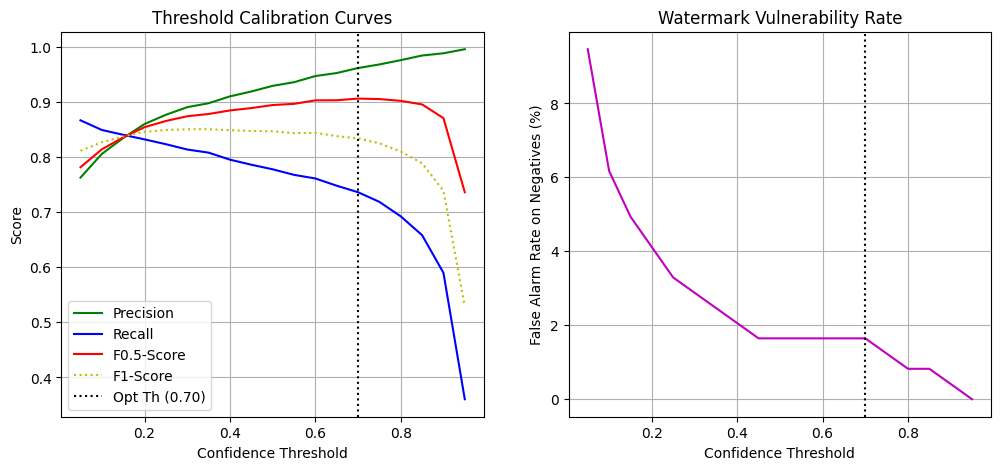

[+] Saved analysis plots to: model_analysis\advanced_calibration_report.png

[*] Exporting worst failure cases under optimal F0.5 threshold (Max Limit: 100)...
[+] Successfully exported 63 False Positive images to: 'model_analysis\false_positives'
[+] Successfully exported 100 False Negative images to: 'model_analysis\false_negatives'


In [2]:
# =====================================================================
# 8. EXECUTION PIPELINE
# =====================================================================
if __name__ == "__main__":
    # 1. Download weights directly from HF
    weights_path = download_weights()
    
    # 2. Instantiate modular YOLO Predictor
    # This wrapper can be swapped for ONNX/TensorRT predictor in the future
    predictor = YOLO26Predictor(weights_path)
    
    # 3. Run the advanced diagnosis engine
    run_deep_evaluation(predictor)

🔍 Знайдено файл логів за шляхом: model_training_results\yolo_training_log.txt
✅ Успішно відновлено 50 епох та збережено в 'results.csv'!
💾 Графік успішно збережено як 'yolo_training_results.png'!


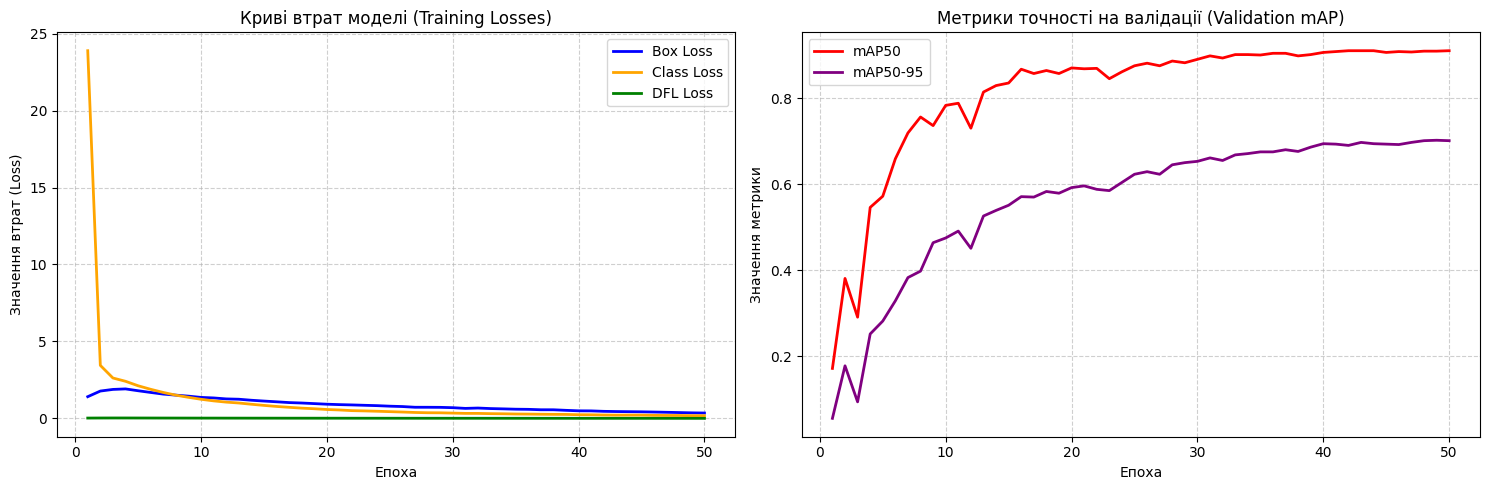

In [4]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

# Список можливих відносних шляхів до файлу
possible_paths = [
    'model_training_results/yolo_training_log.txt',            # якщо запуск з папки notebooks
    'notebooks/model_training_results/yolo_training_log.txt',  # якщо запуск з кореня проекту
    'yolo_training_log.txt'                                    # якщо файл лежить в одній папці
]

log_file_path = None
for path in possible_paths:
    # Нормалізуємо слеші під Windows/Linux
    normalized_path = os.path.normpath(path)
    if os.path.exists(normalized_path):
        log_file_path = normalized_path
        break

if log_file_path is None:
    print("❌ Помилка! Не вдалося автоматично знайти файл 'yolo_training_log.txt'.")
    print(f"Поточна робоча папка ноутбука (cwd): {os.getcwd()}")
    print("Переконайтеся, що файл лежить у 'notebooks/model_training_results/yolo_training_log.txt'")
    log_content = ""
else:
    print(f"🔍 Знайдено файл логів за шляхом: {log_file_path}")
    with open(log_file_path, 'r', encoding='utf-8') as f:
        log_content = f.read()

# Далі йде ваш основний код обробки...
if log_content:
    epochs_data = []
    current_train_metrics = None

    epoch_pattern = re.compile(r'(\d+)/50\s+\S+\s+([\d.]+)\s+([\d.]+)\s+([\d.e-]+)')
    val_pattern = re.compile(r'all\s+\d+\s+\d+\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)')

    for line in log_content.split('\n'):
        epoch_match = epoch_pattern.search(line)
        if epoch_match:
            current_train_metrics = {
                'epoch': int(epoch_match.group(1)),
                'box_loss': float(epoch_match.group(2)),
                'cls_loss': float(epoch_match.group(3)),
                'dfl_loss': float(epoch_match.group(4))
            }
            continue
        
        val_match = val_pattern.search(line)
        if val_match and current_train_metrics is not None:
            current_train_metrics['precision'] = float(val_match.group(1))
            current_train_metrics['recall'] = float(val_match.group(2))
            current_train_metrics['mAP50'] = float(val_match.group(3))
            current_train_metrics['mAP50-95'] = float(val_match.group(4))
            
            epochs_data.append(current_train_metrics)
            current_train_metrics = None

    if epochs_data:
        df = pd.DataFrame(epochs_data)
        
        # Зберігаємо результати поруч із ноутбуком
        df.to_csv('results.csv', index=False)
        print(f"✅ Успішно відновлено {len(df)} епох та збережено в 'results.csv'!")

        # Візуалізація графіків
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        # Графік 1: Криві втрат (Loss Curves)
        axes[0].plot(df['epoch'], df['box_loss'], label='Box Loss', color='blue', linewidth=2)
        axes[0].plot(df['epoch'], df['cls_loss'], label='Class Loss', color='orange', linewidth=2)
        axes[0].plot(df['epoch'], df['dfl_loss'], label='DFL Loss', color='green', linewidth=2)
        axes[0].set_title('Криві втрат моделі (Training Losses)')
        axes[0].set_xlabel('Епоха')
        axes[0].set_ylabel('Значення втрат (Loss)')
        axes[0].legend()
        axes[0].grid(True, linestyle='--', alpha=0.6)

        # Графік 2: Криві точності (mAP)
        axes[1].plot(df['epoch'], df['mAP50'], label='mAP50', color='red', linewidth=2)
        axes[1].plot(df['epoch'], df['mAP50-95'], label='mAP50-95', color='purple', linewidth=2)
        axes[1].set_title('Метрики точності на валідації (Validation mAP)')
        axes[1].set_xlabel('Епоха')
        axes[1].set_ylabel('Значення метрики')
        axes[1].legend()
        axes[1].grid(True, linestyle='--', alpha=0.6)

        plt.tight_layout()
        plt.savefig('yolo_training_results.png', dpi=300)
        print("💾 Графік успішно збережено як 'yolo_training_results.png'!")
        plt.show()

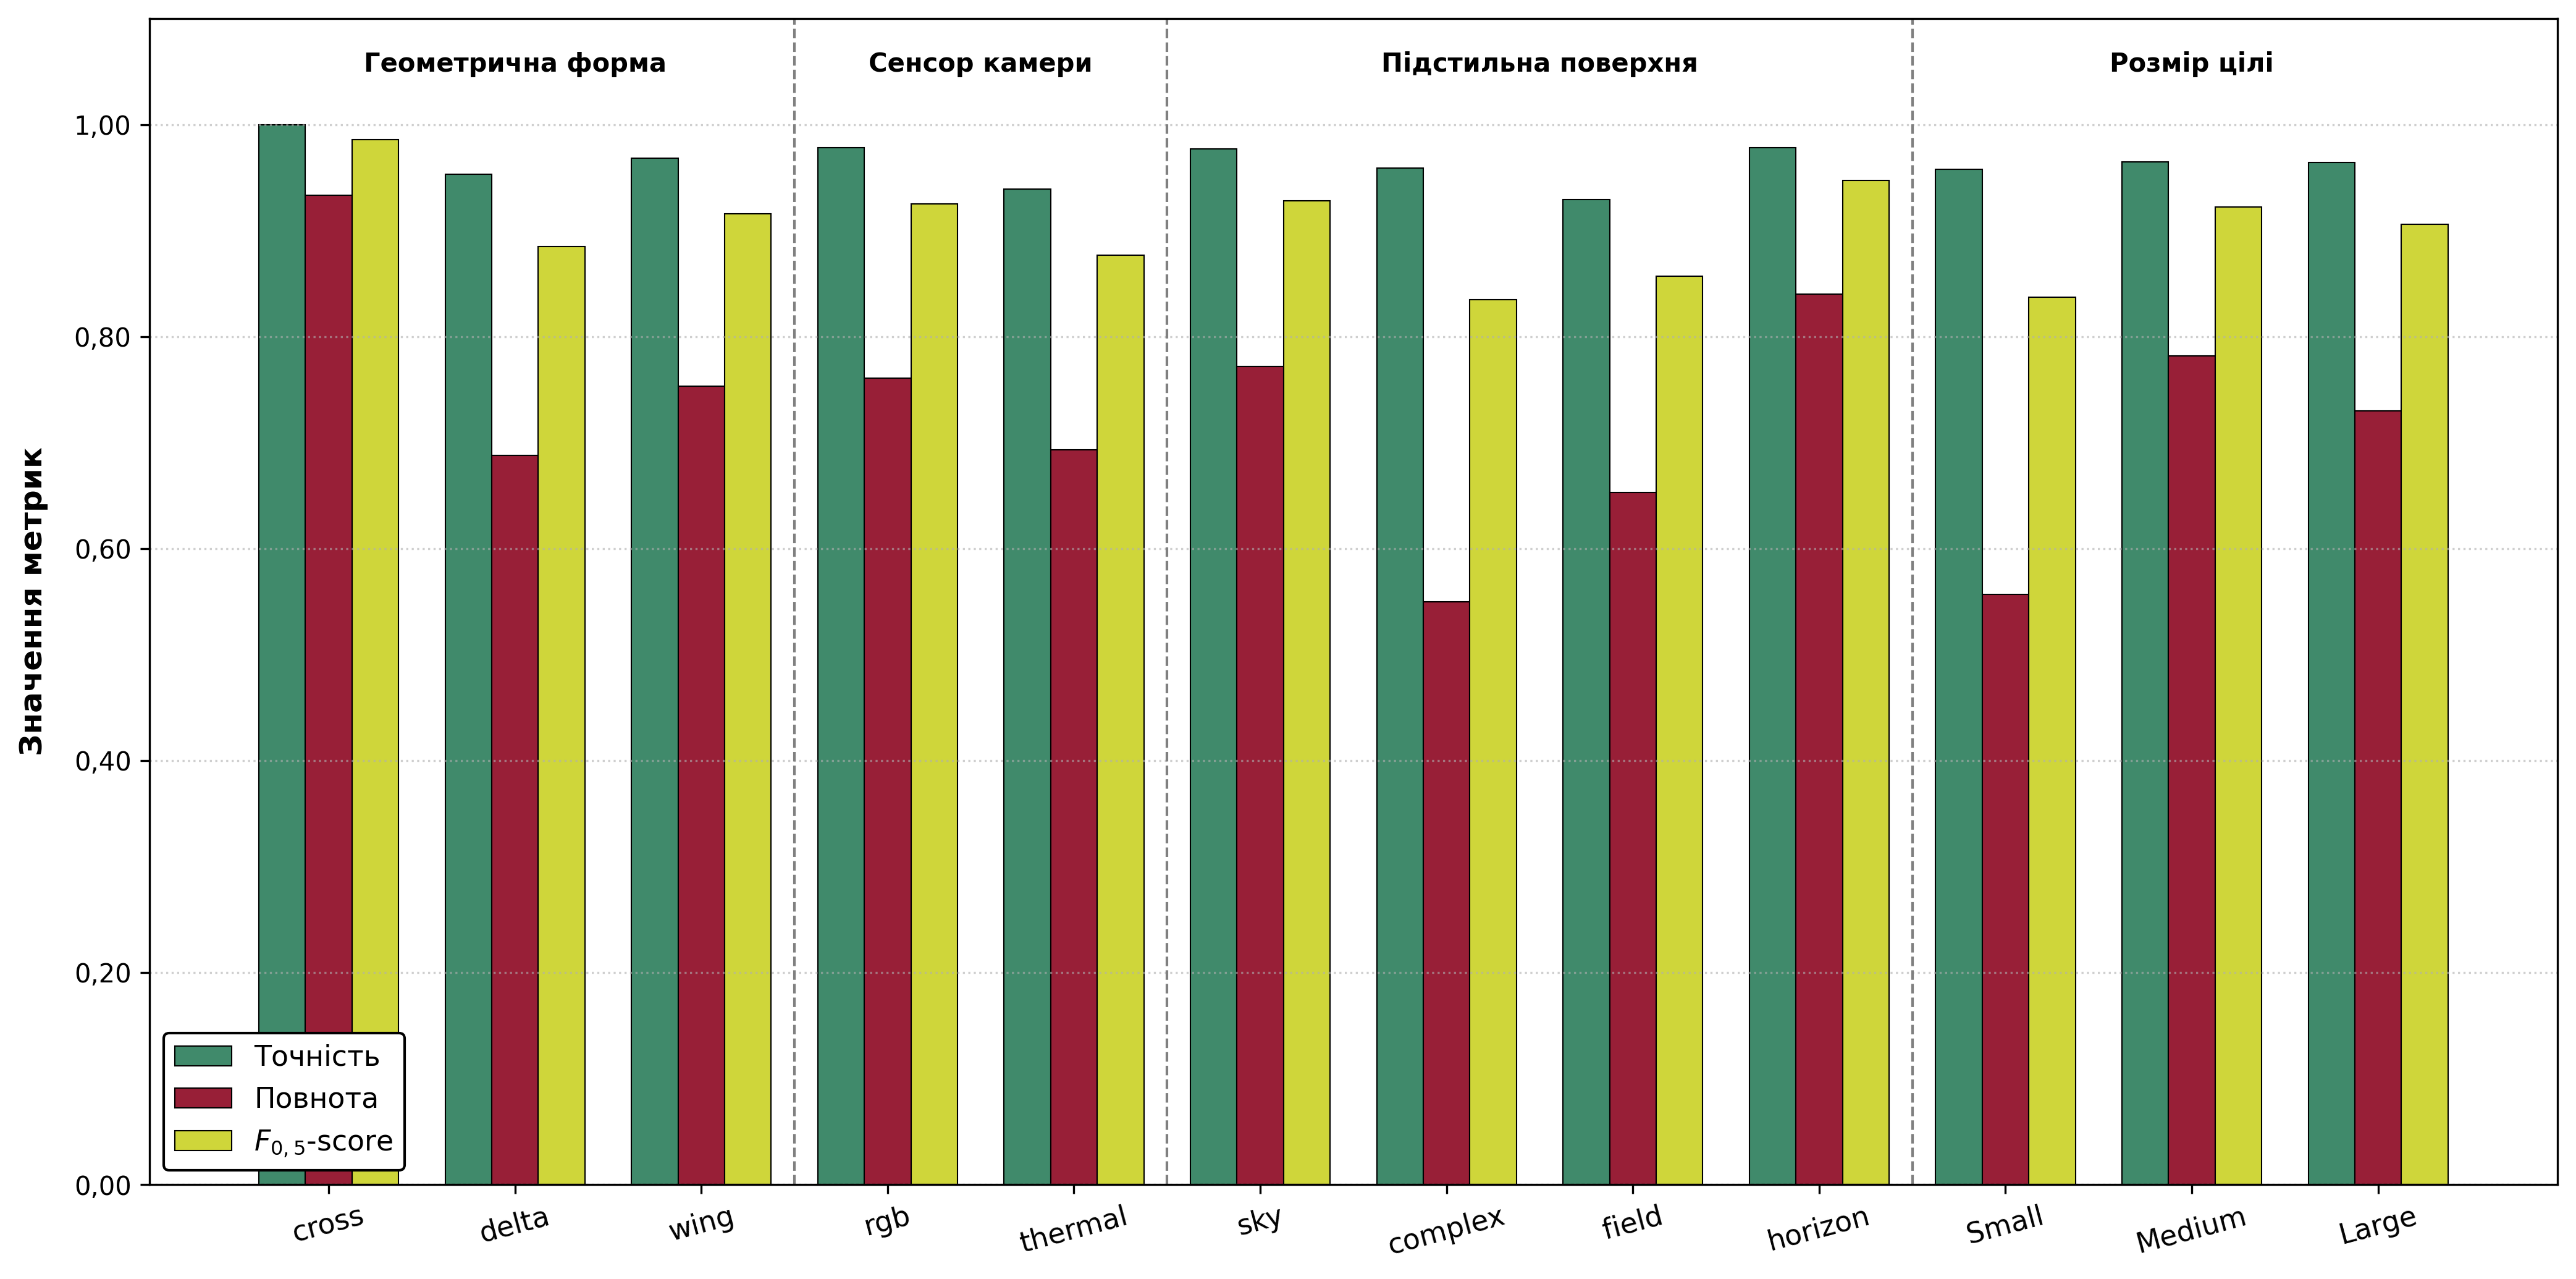

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Підготовка даних (значення з вашої таблиці 4.9)
categories = [
    'cross', 'delta', 'wing',           # Геометрична форма
    'rgb', 'thermal',                   # Сенсор камери
    'sky', 'complex', 'field', 'horizon', # Підстильна поверхня
    'Small', 'Medium', 'Large'          # Розмір цілі
]

precision = [1.000, 0.953, 0.968, 0.978, 0.939, 0.977, 0.959, 0.929, 0.978, 0.958, 0.965, 0.964]
recall =    [0.933, 0.688, 0.753, 0.761, 0.693, 0.772, 0.550, 0.653, 0.840, 0.557, 0.782, 0.730]
f05 =       [0.986, 0.885, 0.916, 0.925, 0.877, 0.928, 0.835, 0.857, 0.947, 0.837, 0.922, 0.906]

# 2. Налаштування геометричних параметрів графіка
x = np.arange(len(categories))  # позиції категорій на осі X
width = 0.25                    # ширина кожного стовпчика

fig, ax = plt.subplots(figsize=(14, 7), dpi=300)

# Побудова стовпчиків (використано стриману академічну палітру кольорів)
rects1 = ax.bar(x - width, precision, width, label='Точність', color="#408a6b", edgecolor='black', linewidth=0.5)
rects2 = ax.bar(x, recall, width, label='Повнота', color="#981f37", edgecolor='black', linewidth=0.5)
rects3 = ax.bar(x + width, f05, width, label='$F_{0,5}$-score', color="#cfd63a", edgecolor='black', linewidth=0.5)

# 3. Додавання розділових ліній між семантичними доменами для читабельності
# Лінії проходять між групами: Форма | Сенсор | Фон | Розмір
ax.axvline(x=2.5, color='gray', linestyle='--', linewidth=1)
ax.axvline(x=4.5, color='gray', linestyle='--', linewidth=1)
ax.axvline(x=8.5, color='gray', linestyle='--', linewidth=1)

# Текстові підписи доменів зверху графіка
ax.text(1, 1.05, 'Геометрична форма', ha='center', fontweight='bold', fontsize=10)
ax.text(3.5, 1.05, 'Сенсор камери', ha='center', fontweight='bold', fontsize=10)
ax.text(6.5, 1.05, 'Підстильна поверхня', ha='center', fontweight='bold', fontsize=10)
ax.text(10, 1.05, 'Розмір цілі', ha='center', fontweight='bold', fontsize=10)

# 4. Налаштування осей та підписів
ax.set_ylabel('Значення метрик', fontsize=12, fontweight='bold', labelpad=10)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11, rotation=15)
ax.set_ylim(0, 1.1)  # невеликий запас зверху для тексту

# Легенда
ax.legend(loc='lower left', fontsize=11, framealpha=1, edgecolor='black')

# Форматування осі Y: замінюємо крапку на кому відповідно до ДСТУ
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f"{val:.2f}".replace('.', ',')))

# Сітка (лише горизонтальна, тонка)
ax.grid(axis='y', linestyle=':', alpha=0.6)

# Оптимізація полів, щоб підписи не обрізалися
plt.tight_layout()

# 5. Збереження зображення у файл високої якості для вставки в Word
plt.savefig('precision_recall_f05_domains.png', bbox_inches='tight', dpi=300)
plt.show()

In [2]:
import os
import cv2
import glob
from pathlib import Path
from huggingface_hub import hf_hub_download
from ultralytics import YOLO
from dotenv import load_dotenv

load_dotenv()

# =====================================================================
# CONFIGURATION
# =====================================================================
REPO_ID = os.getenv("REPO_ID")
HF_TOKEN = os.getenv("HF_TOKEN")

# We use the cross-platform .pt PyTorch file for local PC execution
MODEL_FILENAME = "models/yolo26n_final_model_best.pt"

# The 5 specific paths provided by you
VIDEO_PATHS = [
    r"E:\bachelor_data\dataset_split\test\delta_rgb_field_071.mp4", 
    r"E:\bachelor_data\dataset_split\test\wing_rgb_sky_387.mp4",
    r"E:\bachelor_data\dataset_split\test\delta_rgb_complex_109.mp4",
    r"E:\bachelor_data\dataset_split\test\delta_rgb_field_062.mp4",
    r"E:\bachelor_data\dataset_split\test\wing_thermal_sky_574.mp4"
]

# Destination directory for the annotated videos
OUTPUT_DIR = Path(r"E:\bachelor_data\annotated_results")
CONF_THRESH = 0.70  # Calibrated optimal threshold
IMGSZ = 1280


def download_weights_locally() -> Path:
    """Attempts to load local weights file, otherwise downloads it from Hugging Face."""
    local_pt_path = Path("yolo26n_final_model_best.pt")
    if local_pt_path.exists():
        print(f"[INFO] Found local weights at: {local_pt_path.resolve()}")
        return local_pt_path
        
    print(f"[*] Downloading PyTorch weights from HF Repo '{REPO_ID}'...")
    try:
        downloaded = hf_hub_download(
            repo_id=REPO_ID, 
            filename=MODEL_FILENAME, 
            repo_type="dataset",
            token=HF_TOKEN
        )
        print(f"[+] Weights successfully downloaded to secure cache.")
        return Path(downloaded)
    except Exception as e:
        print(f"[!] HF Download failed: {e}. Checking fallback local files...")
        raise e


def render_demo_videos():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    
    # 1. Resolve weights path (natively handles local or HF cached .pt file)
    weights_path = download_weights_locally()
    
    # 2. Load model
    print("[*] Loading YOLO model...")
    model = YOLO(str(weights_path))
    
    # 3. Process each target video sequence
    for video_path_str in VIDEO_PATHS:
        video_path = Path(video_path_str)
        if not video_path.exists():
            print(f"[WARNING] Video file not found: {video_path}")
            continue
            
        print(f"\n[*] Rendering predictions for: {video_path.name}")
        cap = cv2.VideoCapture(str(video_path))
        
        fps = cap.get(cv2.CAP_PROP_FPS) or 25
        w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        
        out_file = OUTPUT_DIR / f"annotated_{video_path.name}"
        # MP4V codec provides maximum cross-platform compatibility on Windows Media Players
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        writer = cv2.VideoWriter(str(out_file), fourcc, fps, (w, h))
        
        # Generator stream mode to avoid CPU/GPU memory overflow during long runs
        results_generator = model.predict(
            source=str(video_path),
            conf=CONF_THRESH,
            stream=True,
            verbose=False,
            imgsz=IMGSZ
        )
        
        frame_idx = 0
        for result in results_generator:
            frame = result.orig_img.copy()
            
            if result.boxes is not None:
                for box in result.boxes:
                    # Map coordinates to original frame pixel space
                    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                    conf_val = float(box.conf[0])
                    class_id = int(box.cls[0])
                    class_name = model.names[class_id]  # Dynamically fetch class name
                    
                    # Draw bounding box (green)
                    cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
                    # Add label and confidence score
                    cv2.putText(
                        frame,
                        f"{class_name} {conf_val:.2f}",
                        (x1, max(y1 - 5, 10)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.5, (0, 255, 0), 1
                    )
            
            writer.write(frame)
            frame_idx += 1
            
        cap.release()
        writer.release()
        print(f"[+] Successfully saved demonstration video to: {out_file.resolve()}")


if __name__ == "__main__":
    render_demo_videos()

d:\anykn\python\bachelor\drone_classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[*] Downloading PyTorch weights from HF Repo 'hannusia123123/drone_dataset'...
[+] Weights successfully downloaded to secure cache.
[*] Loading YOLO model...

[*] Rendering predictions for: delta_rgb_field_071.mp4
[+] Successfully saved demonstration video to: E:\bachelor_data\annotated_results\annotated_delta_rgb_field_071.mp4

[*] Rendering predictions for: wing_rgb_sky_387.mp4
[+] Successfully saved demonstration video to: E:\bachelor_data\annotated_results\annotated_wing_rgb_sky_387.mp4

[*] Rendering predictions for: delta_rgb_complex_109.mp4
[+] Successfully saved demonstration video to: E:\bachelor_data\annotated_results\annotated_delta_rgb_complex_109.mp4

[*] Rendering predictions for: delta_rgb_field_062.mp4
[+] Successfully saved demonstration video to: E:\bachelor_data\annotated_results\annotated_delta_rgb_field_062.mp4

[*] Rendering predictions for: wing_thermal_sky_574.mp4
[+] Successfully saved demonstration video to: E:\bachelor_data\annotated_results\annotated_wing_th

In [5]:
import os
import cv2
import yaml
from pathlib import Path
from huggingface_hub import hf_hub_download
from ultralytics import YOLO
import ultralytics # Imported to dynamically locate package directories
from dotenv import load_dotenv

load_dotenv()

# =====================================================================
# CONFIGURATION
# =====================================================================
REPO_ID = os.getenv("REPO_ID")
HF_TOKEN = os.getenv("HF_TOKEN")

# We use the cross-platform .pt PyTorch file for local execution
MODEL_FILENAME = "models/yolo26n_final_model_best.pt"

# The 5 specific paths provided by you
VIDEO_PATHS = [
    r"E:\bachelor_data\dataset_split\test\delta_rgb_field_071.mp4", 
    r"E:\bachelor_data\dataset_split\test\wing_rgb_sky_387.mp4",
    r"E:\bachelor_data\dataset_split\test\delta_rgb_complex_109.mp4",
    r"E:\bachelor_data\dataset_split\test\delta_rgb_field_062.mp4",
    r"E:\bachelor_data\dataset_split\test\wing_thermal_sky_574.mp4"
]

# Destination directory for the annotated videos
OUTPUT_DIR = Path(r"E:\bachelor_data\annotated_results")
IMGSZ = 1280

# Best ByteTrack parameters from your experimental grid search (page 108)
TRACKER_CONF = 0.60   # Detection High Threshold (track_high_thresh)
TRACKER_BUFFER = 15   # Frames memory (track_buffer)
TRACK_MATCH_TH = 0.90 # Match threshold (match_thresh)


def download_weights_locally() -> Path:
    """Attempts to load local weights file, otherwise downloads it from Hugging Face."""
    local_pt_path = Path("yolo26n_final_model_best.pt")
    if local_pt_path.exists():
        print(f"[INFO] Found local weights at: {local_pt_path.resolve()}")
        return local_pt_path
        
    print(f"[*] Downloading PyTorch weights from HF Repo '{REPO_ID}'...")
    try:
        downloaded = hf_hub_download(
            repo_id=REPO_ID, 
            filename=MODEL_FILENAME, 
            repo_type="dataset",
            token=HF_TOKEN
        )
        print(f"[+] Weights successfully downloaded to secure cache.")
        return Path(downloaded)
    except Exception as e:
        print(f"[!] HF Download failed: {e}. Checking fallback local files...")
        raise e


def create_custom_tracker_yaml() -> Path:
    """
    Locates the default ByteTrack config inside your installed Ultralytics package,
    overrides your optimal parameters, and saves it dynamically.
    This permanently prevents any missing-key AttributeErrors.
    """
    # Dynamically find the path to the installed 'ultralytics' folder
    ultralytics_dir = Path(ultralytics.__file__).parent
    default_yaml_path = ultralytics_dir / "cfg" / "trackers" / "bytetrack.yaml"
    
    # 1. Load the default package config file to preserve all version-specific keys
    if default_yaml_path.exists():
        with open(default_yaml_path, "r") as f:
            tracker_config = yaml.safe_load(f)
        print(f"[INFO] Loaded installed ByteTrack configuration from: {default_yaml_path.resolve()}")
    else:
        # Fallback configuration (highly unlikely to be triggered)
        tracker_config = {
            "tracker_type": "bytetrack",
            "track_high_thresh": TRACKER_CONF,
            "track_low_thresh": 0.10,
            "new_track_thresh": TRACKER_CONF,
            "track_buffer": TRACKER_BUFFER,
            "match_thresh": TRACK_MATCH_TH,
            "fuse_score": False
        }
        print("[WARNING] default bytetrack.yaml not found. Using fallback config dict.")
        
    # 2. Safely override only your target parameters (maintaining other defaults intact)
    if "track_high_thresh" in tracker_config:
        tracker_config["track_high_thresh"] = TRACKER_CONF
    else:
        # Backward compatibility for older Ultralytics versions
        tracker_config["track_thresh"] = TRACKER_CONF
        
    tracker_config["new_track_thresh"] = TRACKER_CONF
    tracker_config["track_buffer"] = TRACKER_BUFFER
    tracker_config["match_thresh"] = TRACK_MATCH_TH
    
    # 3. Write out custom temporary config file
    yaml_path = Path("custom_bytetrack.yaml")
    with open(yaml_path, "w") as f:
        yaml.dump(tracker_config, f, default_flow_style=False)
    print(f"[+] Created custom tracker configuration file at: {yaml_path.resolve()}")
    return yaml_path


def render_tracker_demo_videos():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    
    # 1. Resolve weights and custom tracker configuration path
    weights_path = download_weights_locally()
    tracker_yaml = create_custom_tracker_yaml()
    
    # 2. Load model
    print("[*] Loading YOLO model...")
    model = YOLO(str(weights_path))
    
    # 3. Process each target video sequence
    for video_path_str in VIDEO_PATHS:
        video_path = Path(video_path_str)
        if not video_path.exists():
            print(f"[WARNING] Video file not found: {video_path}")
            continue
            
        print(f"\n[*] Rendering tracker predictions for: {video_path.name}")
        cap = cv2.VideoCapture(str(video_path))
        
        fps = cap.get(cv2.CAP_PROP_FPS) or 25
        w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        
        out_file = OUTPUT_DIR / f"tracked_{video_path.stem}.mp4"
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        writer = cv2.VideoWriter(str(out_file), fourcc, fps, (w, h))
        
        # We call the 'track' method instead of 'predict' to run ByteTrack
        # We pass persist=True to keep track IDs alive across consecutive frames
        results_generator = model.track(
            source=str(video_path),
            tracker=str(tracker_yaml),
            conf=TRACKER_CONF,
            persist=True,
            stream=True,
            verbose=False,
            imgsz=IMGSZ
        )
        
        frame_idx = 0
        for result in results_generator:
            frame = result.orig_img.copy()
            
            if result.boxes is not None:
                for box in result.boxes:
                    # Map coordinates to original frame pixel space
                    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                    conf_val = float(box.conf[0])
                    
                    # Check if ByteTrack assigned a valid tracking ID to this target
                    if box.id is not None:
                        track_id = int(box.id[0])
                        label_text = f"ID: {track_id} ({conf_val:.2f})"
                    else:
                        label_text = f"drone ({conf_val:.2f})"
                    
                    # Draw bounding box (green)
                    cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
                    # Add tracker ID label and confidence score
                    cv2.putText(
                        frame,
                        label_text,
                        (x1, max(y1 - 5, 10)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.5, (0, 255, 0), 1
                    )
            
            writer.write(frame)
            frame_idx += 1
            
        cap.release()
        writer.release()
        print(f"[+] Successfully saved demonstration video to: {out_file.resolve()}")

    # Clean up temporary configuration file
    if tracker_yaml.exists():
        os.remove(tracker_yaml)


if __name__ == "__main__":
    render_tracker_demo_videos()

[*] Downloading PyTorch weights from HF Repo 'hannusia123123/drone_dataset'...
[+] Weights successfully downloaded to secure cache.
[INFO] Loaded installed ByteTrack configuration from: D:\anykn\python\bachelor\drone_classification\.venv\Lib\site-packages\ultralytics\cfg\trackers\bytetrack.yaml
[+] Created custom tracker configuration file at: D:\anykn\python\bachelor\drone_classification\notebooks\custom_bytetrack.yaml
[*] Loading YOLO model...

[*] Rendering tracker predictions for: delta_rgb_field_071.mp4
[+] Successfully saved demonstration video to: E:\bachelor_data\annotated_results\tracked_delta_rgb_field_071.mp4

[*] Rendering tracker predictions for: wing_rgb_sky_387.mp4
[+] Successfully saved demonstration video to: E:\bachelor_data\annotated_results\tracked_wing_rgb_sky_387.mp4

[*] Rendering tracker predictions for: delta_rgb_complex_109.mp4
[+] Successfully saved demonstration video to: E:\bachelor_data\annotated_results\tracked_delta_rgb_complex_109.mp4

[*] Rendering tra